# 1B. Reporte de simulación del problema asignado

Para esta tarea seleccionamos el Movimiento Browniano Geométrico como el problema a modelelar.

In [ ]:
#importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Analicen el problema asignado e identifiquen las variables, parámetros y condiciones iniciales del modelo

El **Movimiento Browniano Geométrico (MBG)** es el modelo estándar para el
precio de un activo financiero que crece con una tendencia constante y se ve
perturbado por ruido aleatorio proporcional a su propio nivel.

| Símbolo | Descripción | Valor |
|---|---|---|
| $S_0$ | Precio inicial del activo (condición inicial) | $100$ |
| $\mu$ | Rendimiento esperado (drift) anual | $0.08$ |
| $\sigma$ | Volatilidad anual | $0.20$ |
| $\Delta t$ | Paso de tiempo (un trimestre) | $0.25$ |
| $Z_1,Z_2,Z_3,Z_4$ | Normales estándar dadas (ruido aleatorio) | $-0.30,\ 0.80,\ -1.10,\ 0.50$ |
| $\Delta W_k=\sqrt{\Delta t}\,Z_k$ | Incremento browniano en el paso $k$ | (se calcula) |

**Variable de salida:** $S_t$, el precio del activo en cada trimestre
$t=1,2,3,4$ (1 año en total, 4 pasos de $\Delta t=0.25$).


In [ ]:
# analizar problemas, variables, parámetros y condiciones

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

#Los parámetros base--> condiciones iniciales del problema
S0    = 100
mu    = 0.08
sigma = 0.20
dt    = 0.25                 # fracción para un trimestre
Z     = np.array([-0.30, 0.80, -1.10, 0.50])   #normales estándar dadas

print("Parámetros iniciales del problema")
print(f"S0={S0}, mu={mu}, sigma={sigma}, dt={dt}")
print("Z =", Z)


Parámetros iniciales del problema
S0=100, mu=0.08, sigma=0.2, dt=0.25
Z = [-0.3  0.8 -1.1  0.5]


## 3. Formulen el modelo matemático correspondiente y expliquen brevemente el comportamiento esperado del sistema

**Ecuación diferencial estocástica (MBG):**

$$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$$

- El término $\mu S_t\,dt$ es la **tendencia** (crecimiento esperado).
- El término $\sigma S_t\,dW_t$ es el **ruido aleatorio**, proporcional al
  precio actual (por eso "geométrico": las fluctuaciones son en porcentaje,
  no en pesos fijos).

**Esquema numérico (Euler–Maruyama simplificado), tal como pide el problema:**

$$S_{k+1} = S_k\big(1 + \mu\,\Delta t + \sigma\,\Delta W_k\big),
\qquad \Delta W_k = \sqrt{\Delta t}\,Z_k$$

Este esquema aproxima la solución exacta del MBG,
$S_t = S_0\exp\!\big[(\mu-\tfrac12\sigma^2)t + \sigma W_t\big]$, y converge a
ella cuando $\Delta t\to 0$.

**Comportamiento esperado:**

- En promedio, $S_t$ crece de forma exponencial a tasa $\mu$.
- La dispersión de posibles trayectorias crece con $\sigma$: a mayor
  volatilidad, mayor incertidumbre sobre el precio futuro.
- Como el ruido es proporcional a $S_t$, precios más altos generan
  variaciones absolutas más grandes (pero el mismo porcentaje de cambio).
- El precio final $S_T$ sigue una distribución **lognormal** (siempre
  positiva, asimétrica hacia arriba).


## 4.  Implementen una simulación computacional utilizando el lenguaje de programación o software de su elección

Primero replicamos el cálculo manual del problema que hicimos en la tarea pasada (4 pasos, con los $Z_k$
dados). Después generalizamos a una simulación Monte Carlo (muchas
trayectorias aleatorias) para visualizar mejor el comportamiento del modelo.


In [ ]:
def simular_trayectoria(S0, mu, sigma, dt, Z):
    '''esto reproduce el esquema S_(k+1) = S_k (1 + mu*dt + sigma*dW_k) paso a paso.'''
    S = [S0]
    for z in Z:
        dW = np.sqrt(dt) * z
        S.append(S[-1] * (1 + mu * dt + sigma * dW))
    return np.array(S)


#aquí hacemos la replicación del cálculo manual de la tarea previa
S_manual = simular_trayectoria(S0, mu, sigma, dt, Z)
print("Trayectoria manual S0..S4:", S_manual)

#el rendimiento logarítmico total
r_04 = np.log(S_manual[-1] / S_manual[0])
print(f"Rendimiento log. total r_0,4 = {r_04:.6f}  ->  {r_04*100:.4f} %")

#la pérdida/ganancia en pesos (V = 50,000 invertidos al inicio)
V0 = 50_000
n_activos = V0 / S0
delta_V = n_activos * (S_manual[-1] - S_manual[0])
print(f"el numero de activos comprados = {n_activos:.0f}")
print(f"Perdida/ganancia delta_V ~= ${delta_V:,.2f}")


Trayectoria manual S0..S4: [100.       99.      108.9      99.099   106.03593]
Rendimiento log. total r_0,4 = 0.058608  ->  5.8608 %
el numero de activos comprados = 500
Perdida/ganancia delta_V ~= $3,017.97


In [ ]:
def simular_montecarlo(S0, mu, sigma, dt, n_pasos, n_trayectorias, seed=None):
    '''generamos muchas trayectorias GBM con el mismo esquema, usando Z aleatorias.'''
    rng = np.random.default_rng(seed)
    Zsim = rng.standard_normal((n_trayectorias, n_pasos))
    dW = np.sqrt(dt) * Zsim
    factores = 1 + mu * dt + sigma * dW
    caminos = S0 * np.cumprod(factores, axis=1)
    caminos = np.hstack([np.full((n_trayectorias, 1), S0), caminos])
    return caminos


#es la simulación general: 1 año, pasos mas finos (dt=0.05 -> 20 pasos)
T = 1.0
dt_fino = 0.05
n_pasos_fino = int(T / dt_fino)

caminos = simular_montecarlo(S0, mu, sigma, dt_fino, n_pasos_fino, n_trayectorias=30, seed=42)
print("Forma de la matriz de trayectorias (n_trayectorias x n_pasos+1):", caminos.shape)


Forma de la matriz de trayectorias (n_trayectorias x n_pasos+1): (30, 21)


## 5. Resultados visuales

In [ ]:
#visualización tabla del calculo manual
tabla = pd.DataFrame({
    "t (trimestre)": [0, 1, 2, 3, 4],
    "Z_k": [np.nan, *Z],
    "dW_k": [np.nan, *(np.sqrt(dt) * Z)],
    "S_t": S_manual,
})
display(tabla.round(4))


,t (trimestre),Z_k,dW_k,S_t
0,0,NaN,NaN,100.0000
1,1,-0.3,-0.15,99.0000
2,2,0.8,0.40,108.9000
3,3,-1.1,-0.55,99.0990
4,4,0.5,0.25,106.0359


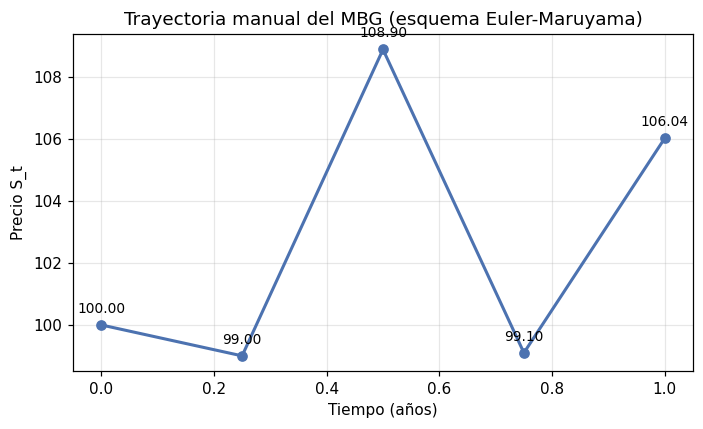

In [ ]:
#visualización en grafica de la trayectoria manual (S0..S4)
t_manual = np.arange(5) * dt
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(t_manual, S_manual, "o-", color="#4C72B0", lw=2)
for ti, si in zip(t_manual, S_manual):
    ax.annotate(f"{si:.2f}", (ti, si), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xlabel("Tiempo (años)")
ax.set_ylabel("Precio S_t")
ax.set_title("Trayectoria manual del MBG (esquema Euler-Maruyama)")
plt.tight_layout()
plt.show()


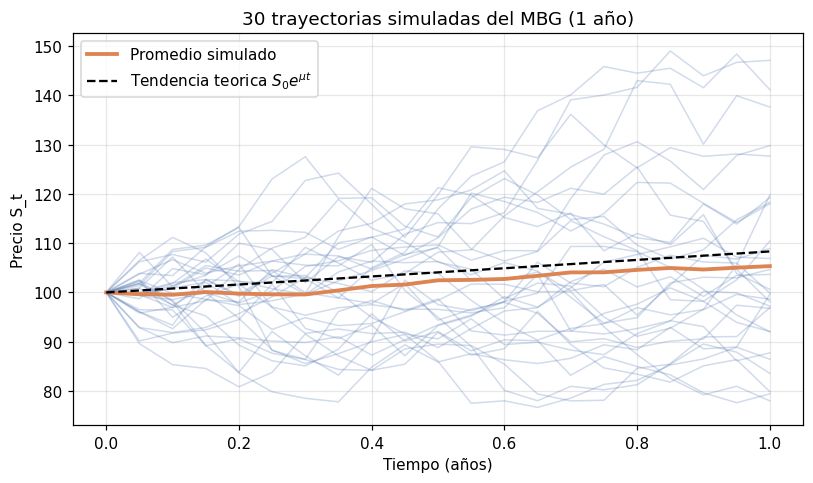

In [ ]:
#el abanico de trayectorias simuladas (Monte Carlo)
t_fino = np.arange(n_pasos_fino + 1) * dt_fino

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(t_fino, caminos.T, color="#4C72B0", alpha=0.25, lw=1)
ax.plot(t_fino, caminos.mean(axis=0), color="#DD8452", lw=2.5, label="Promedio simulado")
ax.plot(t_fino, S0 * np.exp(mu * t_fino), "k--", lw=1.5, label=r"Tendencia teorica $S_0 e^{\mu t}$")
ax.set_xlabel("Tiempo (años)")
ax.set_ylabel("Precio S_t")
ax.set_title("30 trayectorias simuladas del MBG (1 año)")
ax.legend()
plt.tight_layout()
plt.show()


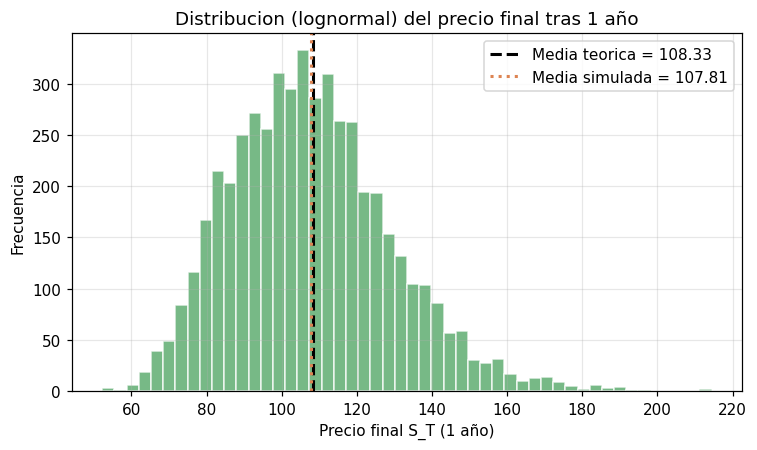

In [ ]:
#distribucion del precio final S_T (histograma)
caminos_hist = simular_montecarlo(S0, mu, sigma, dt_fino, n_pasos_fino, n_trayectorias=5000, seed=1)
S_T = caminos_hist[:, -1]

media_teorica = S0 * np.exp(mu * T)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(S_T, bins=50, color="#55A868", alpha=0.8, edgecolor="white")
ax.axvline(media_teorica, color="black", ls="--", lw=2, label=f"Media teorica = {media_teorica:.2f}")
ax.axvline(S_T.mean(), color="#DD8452", ls=":", lw=2, label=f"Media simulada = {S_T.mean():.2f}")
ax.set_xlabel("Precio final S_T (1 año)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribucion (lognormal) del precio final tras 1 año")
ax.legend()
plt.tight_layout()
plt.show()


El histograma confirma el comportamiento esperado: $S_T$ es asimétrico
hacia la derecha (lognormal) y su media simulada coincide, aproximadamente,
con la media teórica $S_0 e^{\mu T}$.


## 6. Realicen al menos dos modificaciones en los parámetros del modelo y analicen cómo estos cambios afectan los resultados obtenidos

Usamos los **mismos** valores de $Z_k$ del problema original para poder
comparar "manzanas con manzanas": solo cambiamos un parámetro a la vez.

1. **Mayor volatilidad:** $\sigma: 0.20\to 0.45$.
2. **Tendencia bajista:** $\mu: 0.08\to -0.10$.
3. **Paso de tiempo más fino:** $\Delta t: 0.25\to 0.05$ (mismo horizonte de
   1 año, pero con 20 pasos en vez de 4 — se compara vía Monte Carlo, ya que
   ahora se necesitan más números aleatorios que los 4 $Z_k$ originales).


In [ ]:
#primera modificacion 1: sigma mas grande
sigma_mod1 = 0.45
S_mod1 = simular_trayectoria(S0, mu, sigma_mod1, dt, Z)

#segunda modificacion 2: mu negativo (sería una tendencia bajista)
mu_mod2 = -0.10
S_mod2 = simular_trayectoria(S0, mu_mod2, sigma, dt, Z)

#tabla comparativa base vs mod1 vs mod2
comparacion = pd.DataFrame({
    "t (trimestre)": [0, 1, 2, 3, 4],
    "Base (mu=0.08, sigma=0.20)": S_manual,
    "Mod.1: sigma=0.45": S_mod1,
    "Mod.2: mu=-0.10": S_mod2,
}).round(4)
display(comparacion)

print(f"El rendimiento log. total  base = {np.log(S_manual[-1]/S0)*100:.2f} %")
print(f"El rendimiento log. total mod.1 = {np.log(S_mod1[-1]/S0)*100:.2f} %")
print(f"El rendimiento log. total mod.2 = {np.log(S_mod2[-1]/S0)*100:.2f} %")


,t (trimestre),"Base (mu=0.08, sigma=0.20)",Mod.1: sigma=0.45,Mod.2: mu=-0.10
0,0,100.0000,100.0000,100.0000
1,1,99.0000,95.2500,94.5000
2,2,108.9000,114.3000,99.6975
3,3,99.0990,88.2967,86.2383
4,4,106.0359,99.9961,88.3943


El rendimiento log. total  base = 5.86 %
El rendimiento log. total mod.1 = -0.00 %
El rendimiento log. total mod.2 = -12.34 %


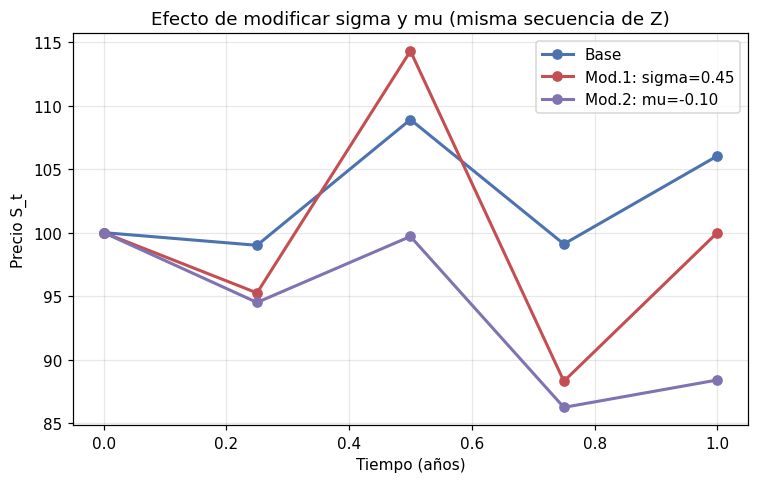

In [ ]:
#visualización grafica comparativa: base vs mod1 vs mod2
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t_manual, S_manual, "o-", label="Base", color="#4C72B0", lw=2)
ax.plot(t_manual, S_mod1, "o-", label="Mod.1: sigma=0.45", color="#C44E52", lw=2)
ax.plot(t_manual, S_mod2, "o-", label="Mod.2: mu=-0.10", color="#8172B2", lw=2)
ax.set_xlabel("Tiempo (años)")
ax.set_ylabel("Precio S_t")
ax.set_title("Efecto de modificar sigma y mu (misma secuencia de Z)")
ax.legend()
plt.tight_layout()
plt.show()


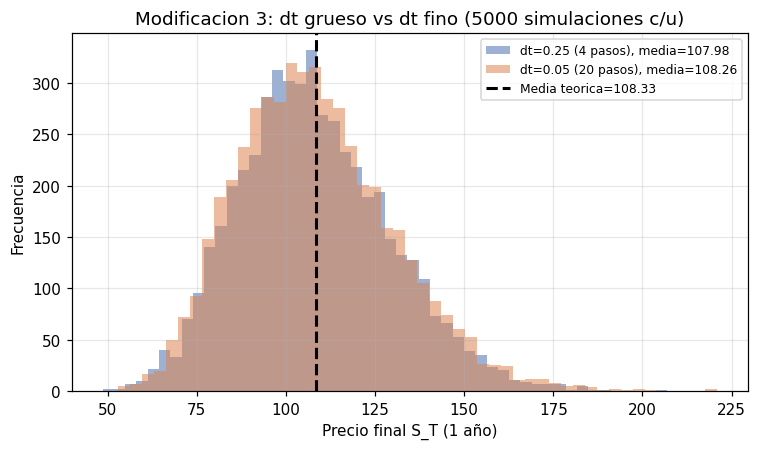

Desv. estandar S_T con dt=0.25: 21.213
Desv. estandar S_T con dt=0.05: 22.093


In [ ]:
#una modificacion 3: dt mas fino (comparacion via Monte Carlo)
dt_grueso, n_pasos_grueso = 0.25, 4    #el esquema original del problema
dt_fino3,  n_pasos_fino3  = 0.05, 20   #mismo horizonte T=1, mas pasos

n_sim = 5000
caminos_grueso = simular_montecarlo(S0, mu, sigma, dt_grueso, n_pasos_grueso, n_sim, seed=7)
caminos_fino3  = simular_montecarlo(S0, mu, sigma, dt_fino3,  n_pasos_fino3,  n_sim, seed=7)

S_T_grueso = caminos_grueso[:, -1]
S_T_fino3  = caminos_fino3[:, -1]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(S_T_grueso, bins=50, alpha=0.55, label=f"dt=0.25 (4 pasos), media={S_T_grueso.mean():.2f}", color="#4C72B0")
ax.hist(S_T_fino3,  bins=50, alpha=0.55, label=f"dt=0.05 (20 pasos), media={S_T_fino3.mean():.2f}", color="#DD8452")
ax.axvline(media_teorica, color="black", ls="--", lw=2, label=f"Media teorica={media_teorica:.2f}")
ax.set_xlabel("Precio final S_T (1 año)")
ax.set_ylabel("Frecuencia")
ax.set_title("Modificacion 3: dt grueso vs dt fino (5000 simulaciones c/u)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Desv. estandar S_T con dt=0.25: {S_T_grueso.std():.3f}")
print(f"Desv. estandar S_T con dt=0.05: {S_T_fino3.std():.3f}")


**Análisis de cada modificación:**

1. **$\sigma:0.20\to0.45$.** Con la misma secuencia de choques $Z_k$, la
   trayectoria se vuelve mucho más errática: los mismos $Z_k$ producen
   subidas y bajadas más pronunciadas, y el rendimiento final cambia de
   forma notable respecto al caso base.

2. **$\mu:0.08\to-0.10$.** La tendencia de fondo se invierte: aunque los
   choques aleatorios ($Z_k$) son los mismos, el precio final tiende a ser
   menor, reflejando un escenario de mercado bajista.

3. **$\Delta t:0.25\to0.05$.** Al usar un paso más pequeño (más simulaciones
   por año), la trayectoria se ve más suave y realista, y — como muestra el
   histograma — la **media** y la **dispersión** del precio final a 1 año son
   muy parecidas entre ambos esquemas: el paso de tiempo afecta la
   *resolución* de la simulación, no el comportamiento promedio de largo
   plazo del modelo (el esquema converge al mismo proceso continuo).


## 7. Elaboren una breve discusión de resultados, incluyendo observaciones, interpretación del comportamiento del sistema y posibles aplicaciones

**Observaciones.**

- El modelo base reproduce exactamente los resultados del problema (resultado de tarea 1A):
  $S_4\approx106.04$, rendimiento log. total $\approx5.86\%$ y una ganancia
  aproximada de \$3,018 al invertir \$50,000.
- $\sigma$ controla qué tan "ruidosa" es la trayectoria: a mayor volatilidad,
  mayor es la posible ganancia y pero también la posible pérdida.
- $\mu$ controla la tendencia de fondo: es la diferencia entre un escenario
  optimista y uno pesimista para el mismo activo.
- $\Delta t$ es un parámetro de la **simulación**, no del activo en sí: al
  refinarlo se obtienen trayectorias más realistas sin cambiar el
  comportamiento esperado a largo plazo (la media y varianza teóricas del
  modelo continuo se conservan).

**Interpretación.** El MBG modela un activo cuyas variaciones porcentuales
(no absolutas) son aleatorias e independientes en el tiempo. Esto explica por
qué el precio nunca se vuelve negativo y por qué su distribución final es
lognormal (asimétrica hacia arriba): las ganancias porcentuales se componen
multiplicativamente.

**Aplicaciones posibles.**

- Valuación de opciones y otros derivados financieros (p. ej. Black–Scholes,
  que asume precios que siguen un MBG).
- Simulación de escenarios (Monte Carlo) para medir riesgo de un portafolio.
- Proyección de flujos futuros de un activo bajo distintos supuestos de
  rendimiento y volatilidad, útil para decisiones de inversión.
